In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from xgboost import XGBRegressor

In [3]:
FILE_PATH = Path("Housing.csv")
data = pd.read_csv(FILE_PATH)

In [4]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,2,38500,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3,49500,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,4,60500,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,5,61000,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [5]:
data.dtypes

rownames      int64
price         int64
lotsize     float64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl    float64
prefarea        str
dtype: object

In [6]:
data.shape

(546, 13)

In [7]:
data.isna().sum()

rownames    0
price       0
lotsize     5
bedrooms    0
bathrms     0
stories     0
driveway    2
recroom     2
fullbase    0
gashw       0
airco       5
garagepl    2
prefarea    2
dtype: int64

In [9]:
data.describe()

,rownames,price,lotsize,bedrooms,bathrms,stories,garagepl
count,546.000000,546.000000,541.000000,546.000000,546.000000,546.000000,544.000000
mean,273.500000,68121.597070,5160.611830,2.965201,1.285714,1.807692,0.694853
std,157.760895,26702.670926,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1.000000,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,137.250000,49125.000000,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,273.500000,62000.000000,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,409.750000,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000
max,546.000000,190000.000000,16200.000000,6.000000,4.000000,4.000000,3.000000


In [14]:
target_col = 'price'
X = data.drop(target_col, axis=1)
y = data[target_col]
X, y

(     rownames  lotsize  bedrooms  bathrms  stories driveway recroom fullbase  \
 0           1   5850.0         3        1        2      yes      no      yes   
 1           2   4000.0         2        1        1      yes      no       no   
 2           3   3060.0         3        1        1      yes      no       no   
 3           4   6650.0         3        1        2      yes     yes       no   
 4           5   6360.0         2        1        1      yes      no       no   
 ..        ...      ...       ...      ...      ...      ...     ...      ...   
 541       542   4800.0         3        2        4      yes     yes       no   
 542       543   6000.0         3        2        4      yes      no       no   
 543       544   6000.0         3        2        4      yes     yes       no   
 544       545   6000.0         3        2        2      yes     yes       no   
 545       546   6000.0         3        1        2      yes      no       no   
 
     gashw airco  garagepl

In [15]:
numeric_features = X.select_dtypes(include='number').columns.to_list()
categorial_features = X.select_dtypes(exclude='number').columns.to_list()

print(f"Target column: {target_col}")
print(f"Numeric features: {len(numeric_features)} | categorial features: {len(categorial_features)}")

Target column: price
Numeric features: 6 | categorial features: 6


In [16]:
# Train 64%, Valid 16%, Test 20%
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train, X_valid, y_train, y_valid = train_test_split(X_tmp, y_tmp, test_size=0.2, random_state=42)

In [17]:
numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),])

categorial_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorial_transformer, categorial_features)
])

In [18]:
preprocessor.fit(X_train)
X_train_transformed = preprocessor.transform(X_train)
X_valid_transformed = preprocessor.transform(X_valid)
X_test_transformed = preprocessor.transform(X_test)

In [20]:
oh = preprocessor.named_transformers_['cat'].named_steps['onehot'] if categorial_features else None
num_names = numeric_features
cat_names = oh.get_feature_names_out(categorial_features).tolist() if oh is not None else []
feature_names = num_names + cat_names
X_train_transformed.shape, X_valid_transformed.shape, X_test_transformed.shape, len(feature_names)

((348, 18), (88, 18), (110, 18), 18)

## XGBoost - Gradient Boosting alqoritminin optimallaşdırılmış və inkişaf etdirirlmiş variantıdır
### Üstünlükləri:
1. Regularization(L1/L2) - modelin ovrfiting-nin qarşısını alır
2. Gradient və Hessian - loss funksiyasının I və II tərtib törəmələrdən istifadə edir
3. Missing values - çatışmayan dəyərlərlə işləmək üçün mexanizmi var
4. Parallel computation - ağacın qurulması zamanı bəzi hesablamalar paralelləşdirir
5. Early stopping - validation nəticəsi yaxşılaşmadıqda təlimi erkən dayandırılması

### XGBoost riyazi məntiqi:
$$
\hat{y}^{(t)} = \hat{y}^{(t-1)} + \eta f_t(x)
$$

- $\hat{y}^{(t)}$ - yeni ümumi proqnoz
- $\hat{y}^{(t-1)}$ - əvvəlki mərhələnin proqnozu
- $f_t(x)$ - yeni ağacın verdiyi düzəliş
- $\eta$ - learning_rate, düzəlişin təsir gücü

In [26]:
xgb = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.01,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    eval_metric="rmse",
    early_stopping_rounds=50,

)
xgb.fit(X_train_transformed, y_train, eval_set=[(X_valid_transformed, y_valid)])

[0]	validation_0-rmse:27229.25549
[1]	validation_0-rmse:27078.20126
[2]	validation_0-rmse:26950.86920
[3]	validation_0-rmse:26769.33494
[4]	validation_0-rmse:26612.66768
[5]	validation_0-rmse:26440.91937
[6]	validation_0-rmse:26294.11744
[7]	validation_0-rmse:26170.63197
[8]	validation_0-rmse:25995.30498
[9]	validation_0-rmse:25876.67323
[10]	validation_0-rmse:25703.60250
[11]	validation_0-rmse:25545.39986
[12]	validation_0-rmse:25404.73313
[13]	validation_0-rmse:25298.11891
[14]	validation_0-rmse:25147.61418
[15]	validation_0-rmse:24993.74471
[16]	validation_0-rmse:24843.59667
[17]	validation_0-rmse:24718.75309
[18]	validation_0-rmse:24587.21833
[19]	validation_0-rmse:24473.33718
[20]	validation_0-rmse:24366.53304
[21]	validation_0-rmse:24255.22186
[22]	validation_0-rmse:24157.76145
[23]	validation_0-rmse:24018.86331
[24]	validation_0-rmse:23923.88372
[25]	validation_0-rmse:23819.87990
[26]	validation_0-rmse:23701.98732
[27]	validation_0-rmse:23611.01436
[28]	validation_0-rmse:23501.2

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [27]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_pred = xgb.predict(X_test_transformed)
print(f"""
R2 (test) : {r2_score(y_test, y_pred):.4f}
RMSE (test) : {rmse(y_test, y_pred):.2f}
Best iteration: {xgb.best_iteration}
""")


R2 (test) : 0.7100
RMSE (test) : 13919.73
Best iteration: 463



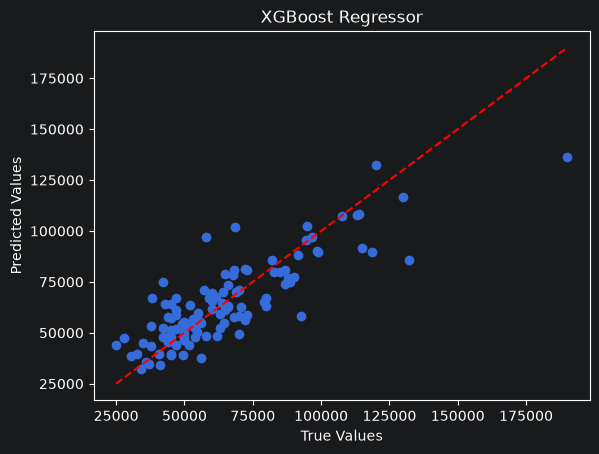

In [28]:
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.title('XGBoost Regressor')
low = min(y_test.min(), y_pred.min())
max = max(y_test.max(), y_pred.max())
plt.plot([low, max], [low, max], 'r--')
plt.show()

In [29]:
importances = xgb.feature_importances_
imp_df = (pd.DataFrame({
    'feature': feature_names if len(feature_names) == len(importances) else [f"feature_{i}" for i in range(len(importances))],
    'importance': importances})
          .sort_values(by='importance', ascending=False).head(10)
)
imp_df

,feature,importance
3,bathrms,0.173269
1,lotsize,0.088700
14,airco_no,0.087125
15,airco_yes,0.071940
12,gashw_no,0.061366
10,fullbase_no,0.059081
11,fullbase_yes,0.055836
13,gashw_yes,0.053761
5,garagepl,0.053726
4,stories,0.047808


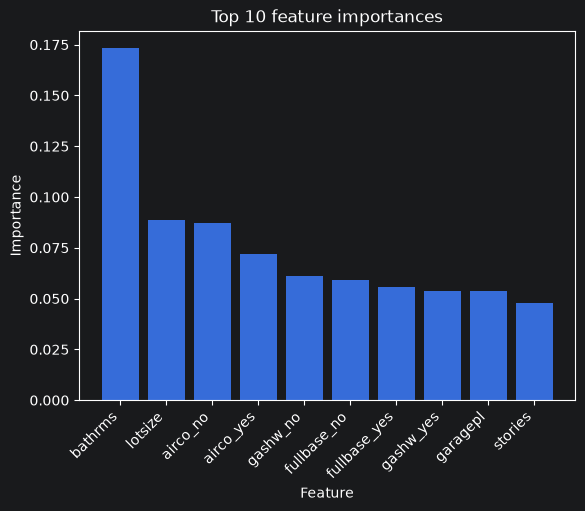

In [30]:
plt.figure()
plt.bar(imp_df['feature'], imp_df['importance'])
plt.title('Top 10 feature importances')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.show()